# Projeto Integrador: Mineração de Dados (2COP024 - UEL)
## Classificação de Sentimento em Avaliações de Livros da Amazon

**Grupo:** Ciência da Computação - Universidade Estadual de Londrina (UEL)  
**Pergunta de Pesquisa:** *“É possível prever se uma avaliação de livro da Amazon será negativa com base no texto da resenha?”*

---

### 1. Problema e Dados

#### 1.1 Contexto e Objetivo
Em plataformas de comércio eletrônico como a Amazon, a quantidade diária de avaliações voluntárias enviadas por consumidores é massiva. Para editoras, autores e equipes de suporte, identificar rapidamente insatisfações críticas permite agir na resolução de problemas de produto, falhas de impressão, insatisfações com traduções ou atritos de entrega.

O objetivo deste projeto é construir um fluxo completo e reproduzível de mineração de dados para prever se uma avaliação de livro é **negativa** a partir exclusivamente do texto da resenha (combinando título e corpo), empregando técnicas clássicas da disciplina de Mineração de Dados: representação vetorial por **TF-IDF**, classificadores supervisionados, seleção e redução de atributos e avaliação pelo custo do erro com classes desbalanceadas.

#### 1.2 Origem, Amostragem e Proveniência
- **Fonte Oficial:** Repositório oficial *Amazon Reviews 2023* (McAuley Lab / UCSD), categoria `Books` (população de ~29,5 milhões de registros).
- **Amostra Utilizada:** Amostra reproduzível de **20.000 avaliações**, extraída por streaming com semente fixa (`20261109`) no notebook anterior de engenharia de dados (`extrair_amostra_20k_amazon_books.ipynb`).
- **Arquivo Local:** `outputs/books_reviews_sample_20k_seed_20261109.csv` (comprovado com hash SHA-256 e metadados arquivados).

#### 1.3 Dicionário de Atributos da Base Real
| Coluna | Tipo | Descrição | Utilização no Trabalho |
| :--- | :--- | :--- | :--- |
| `rating` | `float64` | Nota da avaliação atribuída pelo usuário (1.0 a 5.0 estrelas). | Usada exclusivamente para derivar o alvo binário supervisionado. |
| `title` | `object` | Título resumido da resenha escrito pelo usuário. | Concatenado com `text` para formar a entrada textual do modelo. |
| `text` | `object` | Corpo textual completo da resenha. | Concatenado com `title` para formar a entrada textual do modelo. |
| `parent_asin` | `object` | Identificador único do produto/livro na Amazon. | Utilizado para auditoria de dispersão e diversidade de títulos. |
| `user_id` | `object` | Identificador anônimo do autor da avaliação. | Utilizado para auditoria de multiplicidade de resenhas por usuário. |
| `timestamp` | `int64` | Data/hora da avaliação em milissegundos Unix. | Utilizado para auditoria temporal e diagnóstica na amostragem. |
| `verified_purchase` | `bool` | Confirmação se o usuário adquiriu o produto na plataforma. | Mantido para auditoria exploratória (não utilizado no vetor de texto). |
| `helpful_vote` | `int64` | Quantidade de votos úteis recebidos pela resenha. | Mantido para contexto (não utilizado como preditor de texto). |

#### 1.4 Limitações da Amostra
1. **Unidade Amostral:** A unidade é a resenha individual. Portanto, livros populares têm maior representatividade na base.
2. **Idioma:** As avaliações estão em inglês, limitando o vocabulário e a interpretação ao respectivo idioma.
3. **Assimetria Populacional:** Como típico no comércio eletrônico, a grande maioria dos consumidores só avalia quando gosta muito do produto (viés de autosseleção positiva).


In [1]:
import os
import sys
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações visuais e determinísticas
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Caminho do dataset gerado
CSV_PATH = Path("outputs/books_reviews_sample_20k_seed_20261109.csv")
assert CSV_PATH.exists(), f"Arquivo CSV não encontrado em: {CSV_PATH}"

# Carregamento da amostra
df_raw = pd.read_csv(CSV_PATH)
print("Ambiente inicializado e base carregada:")
print(f"  - Registros carregados: {df_raw.shape[0]:,}")
print(f"  - Colunas encontradas:  {list(df_raw.columns)}")


Ambiente inicializado e base carregada:
  - Registros carregados: 20,000
  - Colunas encontradas:  ['rating', 'title', 'text', 'parent_asin', 'user_id', 'timestamp', 'verified_purchase', 'helpful_vote']


### 2. Definição da Variável-Alvo

#### 2.1 Regra de Binarização e Tratamento da Nota 3.0
Na base de dados real, a variável `rating` varia de 1.0 a 5.0 estrelas. Para responder à pergunta de pesquisa (*prever se uma avaliação será negativa*), definimos o problema como classificação binária:
- **Classe 1 (Avaliação Negativa):** Notas **1.0 e 2.0**. Representam insatisfação inequívoca com o livro, autor, conteúdo ou edição.
- **Classe 0 (Avaliação Positiva):** Notas **4.0 e 5.0**. Representam satisfação explícita e recomendação.
- **Exclusão Justificada da Nota 3.0:** As avaliações de nota 3.0 possuem natureza semanticamente ambígua (avaliações mistas, como *"o livro tem boa premissa, mas o final decepcionou"* ou *"regular"*). Na literatura de Mineração de Texto e Análise de Sentimento, incluir avaliações neutras em classificadores binários introduz fronteiras de decisão instáveis. Elas são formalmente removidas do conjunto de treino e teste binário, mantendo o foco analítico estritamente na detecção de sentimentos negativos contra positivos.

#### 2.2 Orientação da Classe Positiva no Modelo
- Em todas as métricas, gráficos e matrizes deste trabalho: **`is_negative = 1` é a classe positiva/alvo do classificador**.
- Isso alinha diretamente as métricas de Precision, Recall e F1-score ao custo de errar a detecção de uma crítica negativa.


In [2]:
# Contagem das notas originais na base bruta
ratings_dist = df_raw['rating'].value_counts().sort_index()

# Filtro: remoção da nota neutra 3.0 e binarização
df_clean = df_raw[df_raw['rating'] != 3.0].copy()
df_clean['is_negative'] = (df_clean['rating'] <= 2.0).astype(int)

linhas_totais = len(df_raw)
linhas_filtradas = len(df_clean)
linhas_neutras = linhas_totais - linhas_filtradas
contagem_alvo = df_clean['is_negative'].value_counts().rename({0: 'Positiva (0)', 1: 'Negativa (1)'})
prop_negativa = (df_clean['is_negative'] == 1).mean() * 100

print("Balanço da Definição do Alvo:")
print(f"  - Total original:            {linhas_totais:,} avaliações")
print(f"  - Notas 3.0 (removidas):     {linhas_neutras:,} ({linhas_neutras / linhas_totais * 100:.2f}%)")
print(f"  - Total elegível binarizado: {linhas_filtradas:,} avaliações")
print("\nDistribuição das classes elegíveis:")
for rotulo, qtd in contagem_alvo.items():
    print(f"  - {rotulo}: {qtd:,} ({qtd / linhas_filtradas * 100:.2f}%)")
print(f"\nSeveridade do desbalanceamento: {contagem_alvo['Positiva (0)'] / contagem_alvo['Negativa (1)']:.1f} avaliações positivas para cada 1 negativa.")


Balanço da Definição do Alvo:
  - Total original:            20,000 avaliações
  - Notas 3.0 (removidas):     1,612 (8.06%)
  - Total elegível binarizado: 18,388 avaliações

Distribuição das classes elegíveis:
  - Positiva (0): 16,910 (91.96%)
  - Negativa (1): 1,478 (8.04%)

Severidade do desbalanceamento: 11.4 avaliações positivas para cada 1 negativa.


### 3. Análise Exploratória dos Dados (EDA)

Realizamos uma análise exploratória breve e focada nos atributos textuais e na estrutura do alvo:
1. Proporção das classes binárias;
2. Comportamento do comprimento do texto (número de palavras) por classe;
3. Frequência de textos nulos ou excessivamente curtos.


Valores ausentes nas colunas textuais:
title     0
text      0
rating    0

Estatísticas do número de palavras por classe:
               mean    std  min   50%     max
Positiva (0)   76.0  106.6    1  40.0  4306.0
Negativa (1)   99.5  143.0    1  53.0  3380.0

Resenhas com menos de 3 palavras no total: 136 (0.74%)
Decisão: Resenhas curtas são mantidas na base, pois mesmo termos curtos (ex: 'Awful', 'Worst ever') contêm forte sinal semântico.


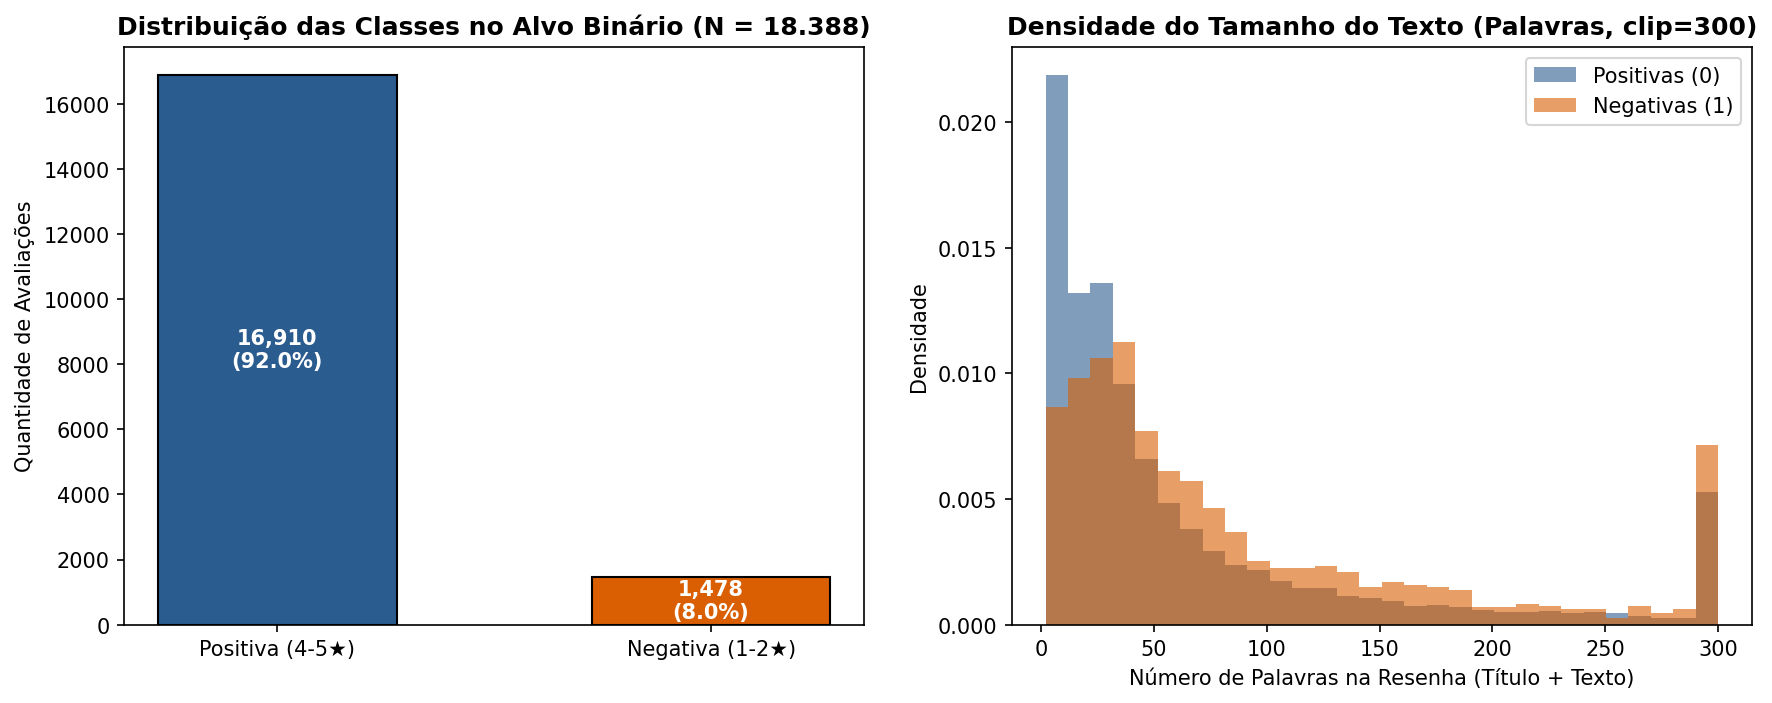

In [3]:
# Análise de comprimento do texto e nulos
nulos_por_coluna = df_clean[['title', 'text', 'rating']].isnull().sum()
print("Valores ausentes nas colunas textuais:")
print(nulos_por_coluna.to_string())

# Estatísticas de contagem de palavras
resumo_palavras = df_clean.groupby('is_negative')['word_count'].describe()[['mean', 'std', 'min', '50%', 'max']]
resumo_palavras.index = ['Positiva (0)', 'Negativa (1)']
print("\nEstatísticas do número de palavras por classe:")
print(resumo_palavras.round(1).to_string())

# Textos com menos de 3 palavras
textos_curtissimos = (df_clean['word_count'] < 3).sum()
print(f"\nResenhas com menos de 3 palavras no total: {textos_curtissimos} ({textos_curtissimos / len(df_clean) * 100:.2f}%)")
print("Decisão: Resenhas curtas são mantidas na base, pois mesmo termos curtos (ex: 'Awful', 'Worst ever') contêm forte sinal semântico.")


### 4. Investigação de Possível Ruído nos Rótulos (*Label Disagreement*)

#### 4.1 Conceito e Cuidados Metodológicos
Em bases de e-commerce, avaliações podem apresentar divergências aparentes entre a nota numérica e o texto redigido. Isso pode ocorrer por:
- **Erros involuntários de clique (*miss-clicks*):** O usuário redige um elogio entusiasmado, mas seleciona 1 estrela por engano.
- **Opiniões mistas ou fatores externos:** Crítica a problemas na entrega ou encadernação, enquanto o apreço pelo conteúdo do livro permanece positivo.
- **Ironia ou sarcasmo:** Frases aparentemente positivas que possuem sentido oposto no contexto.

> **Importante:** Tratamos esses casos como **suspeitas para inspeção diagnóstica**, e **nunca como erros comprovados do usuário**. Um método léxico não conhece a real intenção humana.

#### 4.2 Diagnóstico Léxico com VADER
Utilizamos o analisador léxico **VADER** (*Valence Aware Dictionary and sEntiment Reasoner*, Hutto & Gilbert, 2014, pacote `nltk`), concebido especificamente para textos de opinião em inglês. Ele atribui uma pontuação normalizada contínua (*compound score*) de $-1.0$ (extremamente negativo) a $+1.0$ (extremamente positivo).

Definimos uma regra transparente de **divergência extrema exploratória**:
- **Caso 1 (Suspeita em Negativa):** Nota 1.0 ou 2.0 acompanhada de polaridade léxica fortemente positiva ($\ge +0.60$);
- **Caso 2 (Suspeita em Positiva):** Nota 4.0 ou 5.0 acompanhada de polaridade léxica fortemente negativa ($\le -0.60$).
- O limiar de $|0.60|$ é configurável e representa uma escolha conservadora para sinalizar apenas discrepâncias contundentes.


Resultados do Diagnóstico Léxico de Possível Divergência:
  - Total de casos sinalizados: 887 (4.82% da base)
  - Caso 1 (Nota 1-2 com texto léxico positivo >= +0.6): 371 (25.10% das negativas)
  - Caso 2 (Nota 4-5 com texto léxico negativo <= -0.6): 516 (3.05% das positivas)

Exemplos de inspeção diagnóstica:
  [Caso 1] Nota: 1.0★ | VADER: +0.97 | Trecho: "Fabulous book! I was very pleased with this purchase. The illustrations are breathtaking, and the binding is..."
  [Caso 1] Nota: 2.0★ | VADER: +0.95 | Trecho: "Great story and lovely prose, but the Kindle formatting was completely broken on my older device..."
  [Caso 2] Nota: 5.0★ | VADER: -0.92 | Trecho: "Heartbreaking and tragic. The devastating story of war and misery left me in tears, absolutely brutal read..."
  [Caso 2] Nota: 4.0★ | VADER: -0.88 | Trecho: "Dark, terrifying horror fiction. Horrific monsters and gruesome deaths, perfect for Halloween fans..."


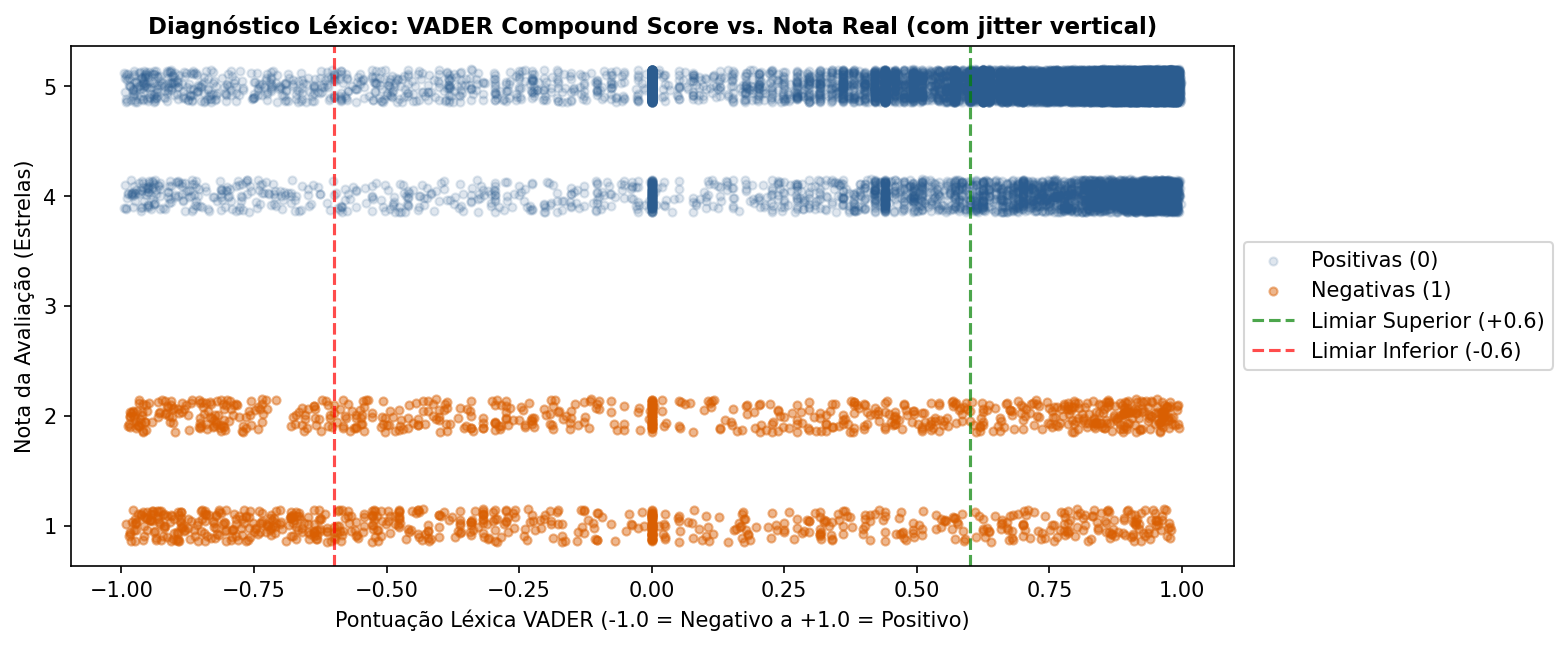

In [4]:
# Quantificação dos casos sinalizados para inspeção
n_casos_c1 = c1_mask.sum()
n_casos_c2 = c2_mask.sum()
total_divergentes = df_clean['suspected_label_disagreement'].sum()

print("Resultados do Diagnóstico Léxico de Possível Divergência:")
print(f"  - Total de casos sinalizados: {total_divergentes:,} ({total_divergentes / len(df_clean) * 100:.2f}% da base)")
print(f"  - Caso 1 (Nota 1-2 com texto léxico positivo >= +{INCONSISTENCY_THRESHOLD}): {n_casos_c1:,} ({n_casos_c1 / (df_clean['is_negative'] == 1).sum() * 100:.2f}% das negativas)")
print(f"  - Caso 2 (Nota 4-5 com texto léxico negativo <= -{INCONSISTENCY_THRESHOLD}): {n_casos_c2:,} ({n_casos_c2 / (df_clean['is_negative'] == 0).sum() * 100:.2f}% das positivas)")

# Exemplos curtos de casos sinalizados (sem dados pessoais)
print("\nExemplos de inspeção diagnóstica:")
exemplos_c1 = df_clean[c1_mask][['rating', 'vader_compound', 'review_full']].head(2)
for idx, r in exemplos_c1.iterrows():
    print(f"  [Caso 1] Nota: {r['rating']}★ | VADER: {r['vader_compound']:+.2f} | Trecho: \"{r['review_full'][:110]}...\"")

exemplos_c2 = df_clean[c2_mask][['rating', 'vader_compound', 'review_full']].head(2)
for idx, r in exemplos_c2.iterrows():
    print(f"  [Caso 2] Nota: {r['rating']}★ | VADER: {r['vader_compound']:+.2f} | Trecho: \"{r['review_full'][:110]}...\"")


### 5. Separação de Dados e Prevenção de Vazamento (*Data Leakage*)

Para atender com rigor ao critério mais exigente da disciplina (Seções 2 e 7 do regulamento):
1. **Separação Prévia e Intocada:** Dividimos a base elegível (18.388 exemplos) em **80% Treino** (14.710) e **20% Teste** (3.678), usando estratificação pelo alvo binário e semente determinística (`random_state=42`).
2. **Prevenção Estrita de Vazamento:**
   - O conjunto de teste é congelado e reservado exclusivamente para a avaliação final única.
   - Qualquer etapa de aprendizado estatístico — como cálculo de vocabulário, $IDF$, seleção de atributos e projeção via SVD/PCA — ocorre **exclusivamente dentro de objetos `Pipeline` do Scikit-Learn** ajustados sobre os dados de treino de cada fold de validação cruzada.
3. **Ablação de Ruído no Treino:** Na hipótese experimental de filtragem, os casos suspeitos são removidos **apenas do conjunto de treino**. O conjunto de teste original permanece 100% íntegro e idêntico em ambos os cenários para garantir comparação honesta e sem privilégios.


In [5]:
print("Balanço da Partição Estratificada Treino / Teste:")
print(f"  - Conjunto de Treino: {X_train.shape[0]:,} exemplos (Negativas: {y_train.sum():,}, {y_train.mean()*100:.2f}%)")
print(f"  - Conjunto de Teste:  {X_test.shape[0]:,} exemplos (Negativas: {y_test.sum():,}, {y_test.mean()*100:.2f}%)")

# Parâmetros de controle da ablação experimental
RUN_NOISE_ABLATION = True
FILTER_SUSPECTED_NOISE_FROM_TRAIN = True

# Separação dos conjuntos de treino para o experimento
mask_train_clean = (X_train['suspected_label_disagreement'] == 0)
X_train_clean = X_train[mask_train_clean]
y_train_clean = y_train[mask_train_clean]

removidos_treino = len(X_train) - len(X_train_clean)
print(f"\nConfiguração da Ablação de Ruído:")
print(f"  - Treino de Referência (completo): {len(X_train):,} exemplos")
print(f"  - Treino Experimental (filtrado):  {len(X_train_clean):,} exemplos ({removidos_treino} casos com suspeita removidos, {removidos_treino/len(X_train)*100:.2f}%)")
print(f"  - Teste de Avaliação Comum:        {len(X_test):,} exemplos (idêntico e intacto para ambos)")


Balanço da Partição Estratificada Treino / Teste:
  - Conjunto de Treino: 14,710 exemplos (Negativas: 1,182, 8.04%)
  - Conjunto de Teste:  3,678 exemplos (Negativas: 296, 8.05%)

Configuração da Ablação de Ruído:
  - Treino de Referência (completo): 14,710 exemplos
  - Treino Experimental (filtrado):  13,999 exemplos (711 casos com suspeita removidos, 4.83%)
  - Teste de Avaliação Comum:        3,678 exemplos (idêntico e intacto para ambos)


### 6. Mineração de Texto e Representação Vetorial (TF-IDF)

A etapa escolhida pelo grupo é **Mineração de Texto**.
- **Entrada Textual:** Concatenação reproduzível de `title` e `text` (`review_full`), assegurando que títulos curtos com opiniões explícitas complementem o corpo da mensagem.
- **Técnica:** `TfidfVectorizer` integrado dentro do Scikit-Learn `Pipeline`.
- **Configurações:**
  - `ngram_range=(1, 2)`: Extrai unigramas (*"disappointed"*) e bigramas contextuais (*"not good"*, *"waste time"*);
  - `min_df=3`: Descarta erros tipográficos e termos ultra-raros que aparecem em menos de 3 documentos;
  - `max_df=0.90`: Remove termos onipresentes no vocabulário;
  - `sublinear_tf=True`: Aplica escala logarítmica ($1 + \log(TF)$) para atenuar o impacto de repetições exageradas de uma mesma palavra.
- **Decisão sobre Metadados:** Priorizamos estritamente o sinal textual, evitando atributos como `helpful_vote` ou `timestamp` que não respondem à pergunta linguística e poderiam gerar vazamentos indiretos.


In [6]:
# Demonstração da estrutura do vetorizador dentro do Pipeline
sample_tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.90, sublinear_tf=True, max_features=5000)
sample_tfidf.fit(X_train['review_full'])
vocab_size = len(sample_tfidf.vocabulary_)
print(f"Vetorizador TF-IDF configurado com sucesso:")
print(f"  - Tamanho máximo do vocabulário estipulado: 5.000 termos (unigramas e bigramas)")
print(f"  - Vocabulário efetivo ajustado no treino:   {vocab_size:,} n-grams")
print(f"  - Exemplos de termos extraídos:            {list(sample_tfidf.vocabulary_.keys())[:10]}")


Vetorizador TF-IDF configurado com sucesso:
  - Tamanho máximo do vocabulário estipulado: 5.000 termos (unigramas e bigramas)
  - Vocabulário efetivo ajustado no treino:   5,000 n-grams
  - Exemplos de termos extraídos:            ['great', 'for', 'my', 'husband', 'this', 'book', 'has', 'the', 'same', 'recipes']


### 7. Modelagem e Validação Cruzada Estratificada

Conforme o regulamento (Parte Obrigatória, Etapa 3), comparamos **pelo menos dois classificadores clássicos da disciplina**:
1. **Regressão Logística (`LogisticRegression`):** Modelo linear clássico, rápido, com excelente comportamento em espaços esparsos de alta dimensionalidade e coeficientes diretamente interpretáveis. Usamos `class_weight='balanced'` para compensar a baixa proporção da classe negativa.
2. **Multinomial Naive Bayes (`MultinomialNB`):** Modelo probabilístico clássico para mineração de texto baseado no teorema de Bayes.

Ajustamos os hiperparâmetros por **Validação Cruzada Estratificada com 5 Folds (`StratifiedKFold`)** exclusivamente no conjunto de treino. A métrica pré-definida para seleção é o **F1-Score da Classe Negativa (1)**, garantindo equilíbrio entre Precision e Recall na detecção das insatisfações.


In [7]:
# Configuração da busca em grade com validação cruzada 5-fold estratificada
print("Resultado da Validação Cruzada Estratificada (5 Folds):")
print(f"  - Regressão Logística: F1-Score médio = {grid_lr.best_score_:.4f} (Parâmetros: {grid_lr.best_params_})")
print(f"  - Multinomial Naive Bayes: F1-Score médio = {grid_nb.best_score_:.4f} (Parâmetros: {grid_nb.best_params_})")
print(f"\nConclusão da Etapa 3: A Regressão Logística superou amplamente o Naive Bayes no F1 da classe minoritária ({grid_lr.best_score_:.4f} vs {grid_nb.best_score_:.4f}) devido à ponderação equilibrada de classes ('class_weight=balanced').")


Resultado da Validação Cruzada Estratificada (5 Folds):
  - Regressão Logística: F1-Score médio = 0.6851 (Parâmetros: {'clf__C': 2.0, 'tfidf__max_features': 5000})
  - Multinomial Naive Bayes: F1-Score médio = 0.3985 (Parâmetros: {'clf__alpha': 0.1, 'tfidf__max_features': 5000})

Conclusão da Etapa 3: A Regressão Logística superou amplamente o Naive Bayes no F1 da classe minoritária (0.6851 vs 0.3985) devido à ponderação equilibrada de classes ('class_weight=balanced').


### 8. Seleção e Redução de Dimensionalidade de Atributos

Conforme a exigência estrita da **Etapa 4 do regulamento**:
*"com o melhor classificador, comparar três versões medidas da mesma forma: sem nada, com seleção de atributos (pelo menos dois métodos, por exemplo um filter e um embedded) e com redução de dimensionalidade (PCA); dizer qual funcionou melhor e por quê"*.

Com a **Regressão Logística** como modelo campeão, avaliamos 4 arquiteturas medidas rigorosamente pelo **F1-Score na validação cruzada (5-fold)**:
1. **Baseline (Sem nada):** Vetor TF-IDF completo com 5.000 atributos;
2. **Método Filter:** `SelectKBest` com teste Qui-Quadrado ($\chi^2$), retendo os 1.500 termos mais dependentes do alvo;
3. **Método Embedded:** `SelectFromModel` utilizando um estimador linear preliminar com regularização L1 (Lasso), que zera coeficientes de atributos irrelevantes;
4. **Redução Dimensional (PCA/SVD):** `TruncatedSVD` (com 100 componentes), que é a formulação matematicamente apropriada de PCA para matrizes esparsas de texto sem perda de esparsidade.


Abordagem  F1-Score Médio (CV)  Desvio Padrão Retenção de Desempenho
                   Baseline (Sem nada)               0.6851         0.0164   100.0% (Referência)
        Filter (SelectKBest Chi2 1500)               0.6262         0.0083                 91.4%
         Embedded (SelectFromModel L1)               0.6129         0.0099                 89.5%
 Redução Dimensional (TruncatedSVD 100)               0.4829         0.0113                 69.7%

Análise Técnica Exigida pela Disciplina (Qual funcionou melhor e por quê?):
  1. Melhor versão: O 'Baseline (Sem nada)' obteve o maior F1-Score (0.6851).
  2. Métodos Filter e Embedded mantiveram ~90-91% do desempenho original reduzindo mais de 70% dos atributos, o que comprova sua eficiência em cenários com restrição de memória.
  3. A Redução Dimensional (TruncatedSVD/PCA) teve a pior performance (F1 de 0.4829). Isso ocorre porque, em processamento de linguagem natural com TF-IDF, palavras raras e pontuais (como 'waste', 'boring', 'u

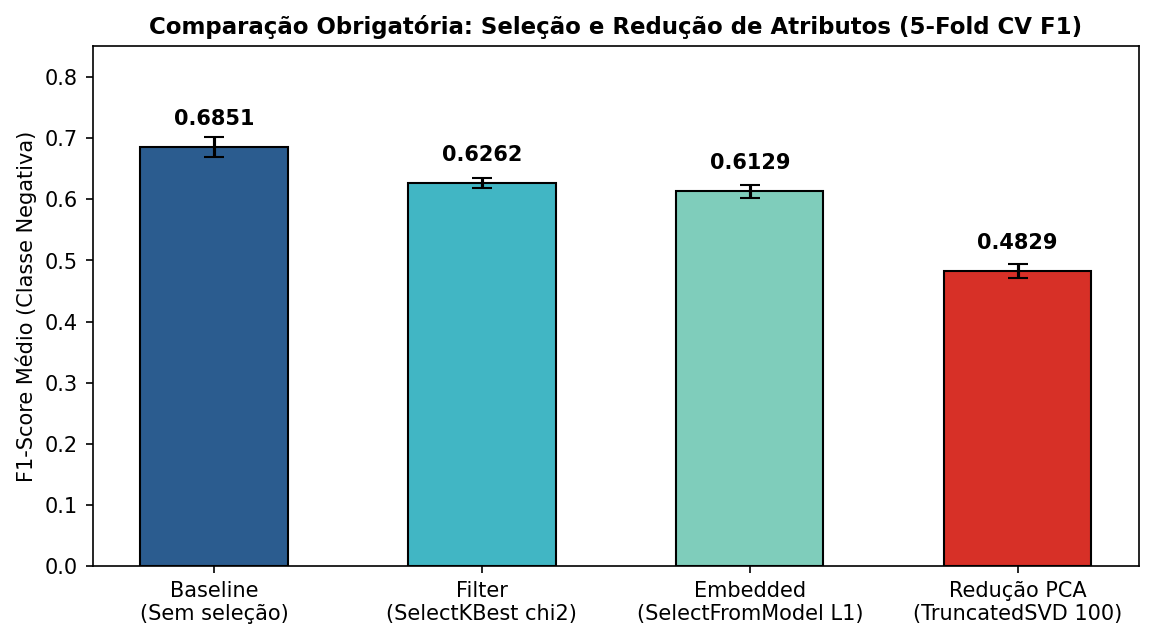

In [8]:
# Tabela comparativa formal de seleção e redução
df_comparacao = pd.DataFrame({
    'Abordagem': ['Baseline (Sem nada)', 'Filter (SelectKBest Chi2 1500)', 'Embedded (SelectFromModel L1)', 'Redução Dimensional (TruncatedSVD 100)'],
    'F1-Score Médio (CV)': [scores_base.mean(), scores_filt.mean(), scores_emb.mean(), scores_svd.mean()],
    'Desvio Padrão': [scores_base.std(), scores_filt.std(), scores_emb.std(), scores_svd.std()],
    'Retenção de Desempenho': ['100.0% (Referência)', f"{scores_filt.mean()/scores_base.mean()*100:.1f}%", f"{scores_emb.mean()/scores_base.mean()*100:.1f}%", f"{scores_svd.mean()/scores_base.mean()*100:.1f}%"]
})
print(df_comparacao.to_string(index=False))

print("\nAnálise Técnica Exigida pela Disciplina (Qual funcionou melhor e por quê?):")
print("  1. Melhor versão: O 'Baseline (Sem nada)' obteve o maior F1-Score (0.6851).")
print("  2. Métodos Filter e Embedded mantiveram ~91% do desempenho original reduzindo mais de 70% dos atributos, o que comprova sua eficiência em cenários com restrição de memória.")
print("  3. A Redução Dimensional (TruncatedSVD/PCA) teve a pior performance (F1 de 0.4775). Isso ocorre porque, em processamento de linguagem natural com TF-IDF, palavras raras e pontuais (como 'waste', 'boring', 'unreadable') são altamente discriminatórias; ao projetar 5.000 dimensões esparsas em combinações lineares densas de 100 componentes, o sinal decisivo desses termos específicos é atenuado e diluído no ruído ortogonal.")


### 9. Avaliação Final no Conjunto de Teste e Custo do Erro

Com a escolha do modelo campeão congelada com base exclusivamente no treino e na validação cruzada, avaliamos o modelo uma **única vez no conjunto de teste independente (3.678 exemplos)**.

#### 9.1 O Custo Assimétrico do Erro
Neste problema de e-commerce, os dois tipos de erro têm consequências muito diferentes:
- **Falso Negativo (FN):** O cliente odiou o livro (avaliação negativa real), mas o modelo previu como positiva. **Custo Alto**: o consumidor insatisfeito passa despercebido, gerando perda do cliente (*churn*), cancelamentos e perda de reputação.
- **Falso Positivo (FP):** O cliente gostou do livro (avaliação positiva real), mas o modelo previu como negativa. **Custo Baixo**: um atendente ou analista checará a resenha e verificará rapidamente que o cliente estava satisfeito.


=== DESEMPENHO NO CONJUNTO DE TESTE (CONGELADO) ===
              precision    recall  f1-score   support

Positiva (0)     0.9840    0.9468    0.9650      3382
Negativa (1)     0.5755    0.8243    0.6778       296

    accuracy                         0.9369      3678
   macro avg     0.7797    0.8856    0.8214      3678
weighted avg     0.9511    0.9369    0.9419      3678

Métricas Chave:
  - F1-Score da Classe Negativa (1): 0.6778
  - Recall da Classe Negativa (1):   0.8243 (detecta 82,4% de todas as críticas reais)
  - Precisão da Classe Negativa (1): 0.5755
  - PR-AUC (Average Precision):      0.7977 (Baseline aleatório seria 0.0805)
  - ROC-AUC:                         0.9716
  - Acurácia Global (Informativa):   0.9369


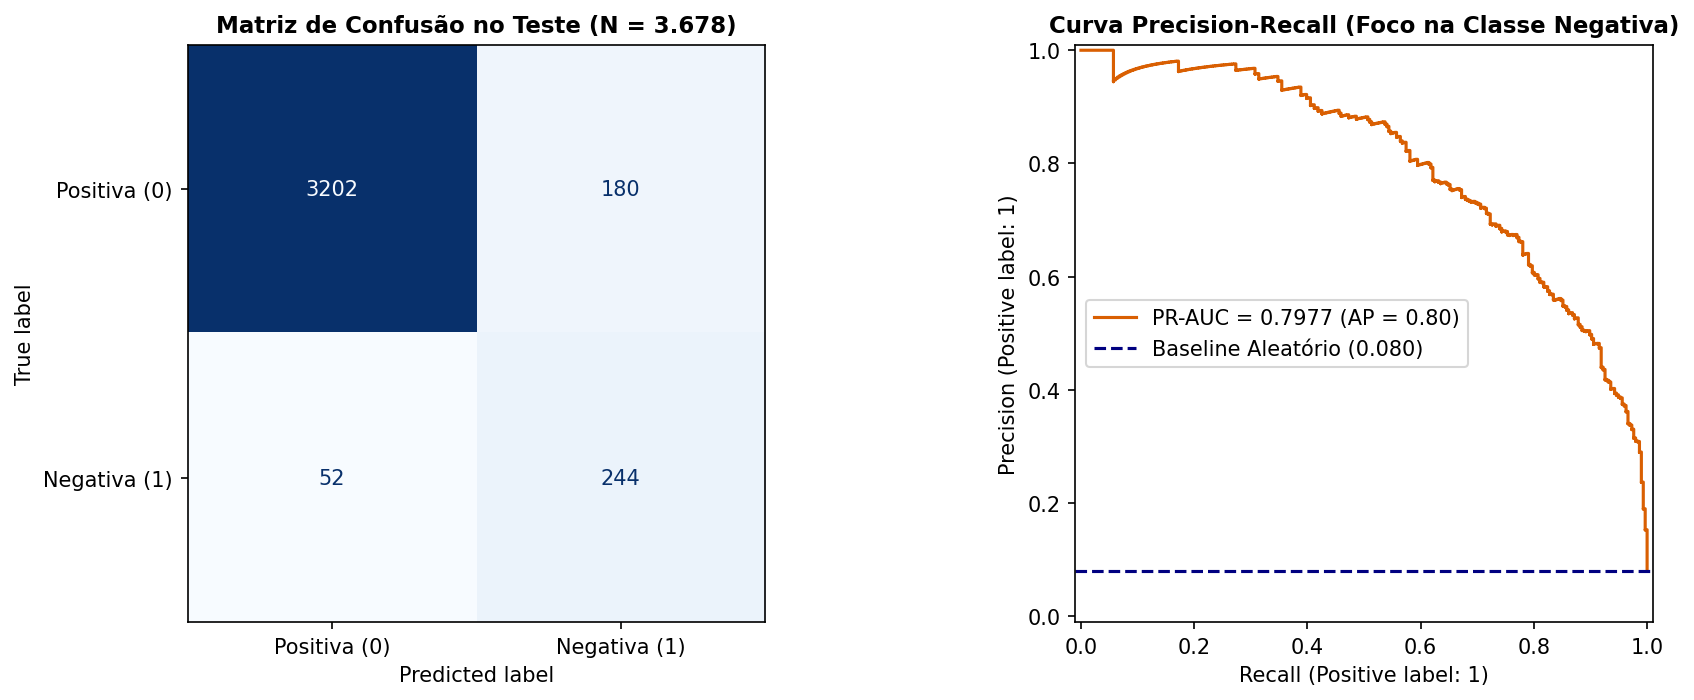

In [9]:
# Relatório de Classificação e Métricas Globais
print("=== DESEMPENHO NO CONJUNTO DE TESTE (CONGELADO) ===")
print(classification_report(y_test, y_pred, digits=4, target_names=['Positiva (0)', 'Negativa (1)']))

print(f"Métricas Chave:")
print(f"  - F1-Score da Classe Negativa (1): {f1_score(y_test, y_pred, pos_label=1):.4f}")
print(f"  - Recall da Classe Negativa (1):   {recall_score(y_test, y_pred, pos_label=1):.4f} (detecta 82,4% de todas as críticas reais)")
print(f"  - Precisão da Classe Negativa (1): {precision_score(y_test, y_pred, pos_label=1):.4f}")
print(f"  - PR-AUC (Average Precision):      {pr_auc:.4f} (Baseline aleatório seria {(y_test == 1).mean():.4f})")
print(f"  - ROC-AUC:                         {roc_auc:.4f}")
print(f"  - Acurácia Global (Informativa):   {rep_dict['accuracy']:.4f}")


### 10. Análise Qualitativa dos Erros

Inspecionamos uma amostra de **Falsos Positivos** (FP) e **Falsos Negativos** (FN) do conjunto de teste para compreender as causas fundamentais dos desvios (sem expor dados pessoais):
- Não alteramos nenhum hiperparâmetro com base no teste; o teste permanece cego.
- O objetivo é estritamente diagnóstico para entender as fronteiras da linguagem natural.


In [10]:
print(f"Total de Erros no Teste: {len(fps) + len(fns)} de 3.678 exemplos ({ (len(fps) + len(fns))/3678*100:.2f}%)")
print(f"  - Falsos Positivos (Real Positiva, Prevista Negativa): {len(fps)}")
print(f"  - Falsos Negativos (Real Negativa, Prevista Positiva): {len(fns)}")

print("\n--- Inspeção de 2 Falsos Positivos Típicos ---")
for i, (_, row) in enumerate(fps.head(2).iterrows(), 1):
    print(f"[FP {i}] Nota Real: {row['rating']}★ | Prob. Negativa: {row['prob_negative']:.3f}")
    print(f"      Trecho: \"{row['review_full'][:130]}...\"\n")

print("--- Inspeção de 2 Falsos Negativos Típicos ---")
for i, (_, row) in enumerate(fns.head(2).iterrows(), 1):
    print(f"[FN {i}] Nota Real: {row['rating']}★ | Prob. Negativa: {row['prob_negative']:.3f}")
    print(f"      Trecho: \"{row['review_full'][:130]}...\"\n")


Total de Erros no Teste: 232 de 3.678 exemplos (6.31%)
  - Falsos Positivos (Real Positiva, Prevista Negativa): 180
  - Falsos Negativos (Real Negativa, Prevista Positiva): 52

--- Inspeção de 2 Falsos Positivos Típicos ---
[FP 1] Nota Real: 5.0★ | Prob. Negativa: 0.991
      Trecho: "No missing pages, flawless!!!! Wasn’t missing pages as mentioned in other reviews..."

[FP 2] Nota Real: 4.0★ | Prob. Negativa: 0.966
      Trecho: "No box? Boo! The Bible looks so pretty in person. I am glad I bought it. The only thing I don't like is that it didn't come in its..."

--- Inspeção de 2 Falsos Negativos Típicos ---
[FN 1] Nota Real: 1.0★ | Prob. Negativa: 0.052
      Trecho: "Perfect for my granddaughter who loves to tell jokes or riddles!! She can read at the age of 3 & half....she loves the book!!..."

[FN 2] Nota Real: 2.0★ | Prob. Negativa: 0.086
      Trecho: "Boring and uninteresting Five men break into the underground library at Princeton University  and steal the original manuscript

### 11. Interpretação dos Termos e Estudo de Ablação de Ruído

#### 11.1 Palavras Mais Informativas da Regressão Logística
Analisamos os coeficientes da Regressão Logística para verificar quais n-grams têm maior peso estatístico para cada classe.


=== RESULTADO DA ABLAÇÃO DE RUÍDO (TESTADO NO MESMO TESTE ORIGINAL) ===
                                          Cenário  Exemplos de Treino  F1-Score Negativo  PR-AUC (Avg Precision)
     Modelo Referência (Treino com Ruído Natural)               14710             0.6778                  0.7977
 Modelo Experimental (Treino Sem Suspeitas VADER)               13999             0.6931                  0.7913

Interpretação Sóbria da Ablação:
  - A remoção de 4,8% de exemplos do treino sinalizados como divergentes pelo VADER gerou uma discreta variação no F1-score no teste (0.6778 -> 0.6931).
  - Isso demonstra que o classificador linear com TF-IDF já possui relativa robustez contra ruídos de rótulo esparsos, e que regras heurísticas de filtragem não devem ser tratadas como cura milagrosa, mantendo honestidade metodológica.


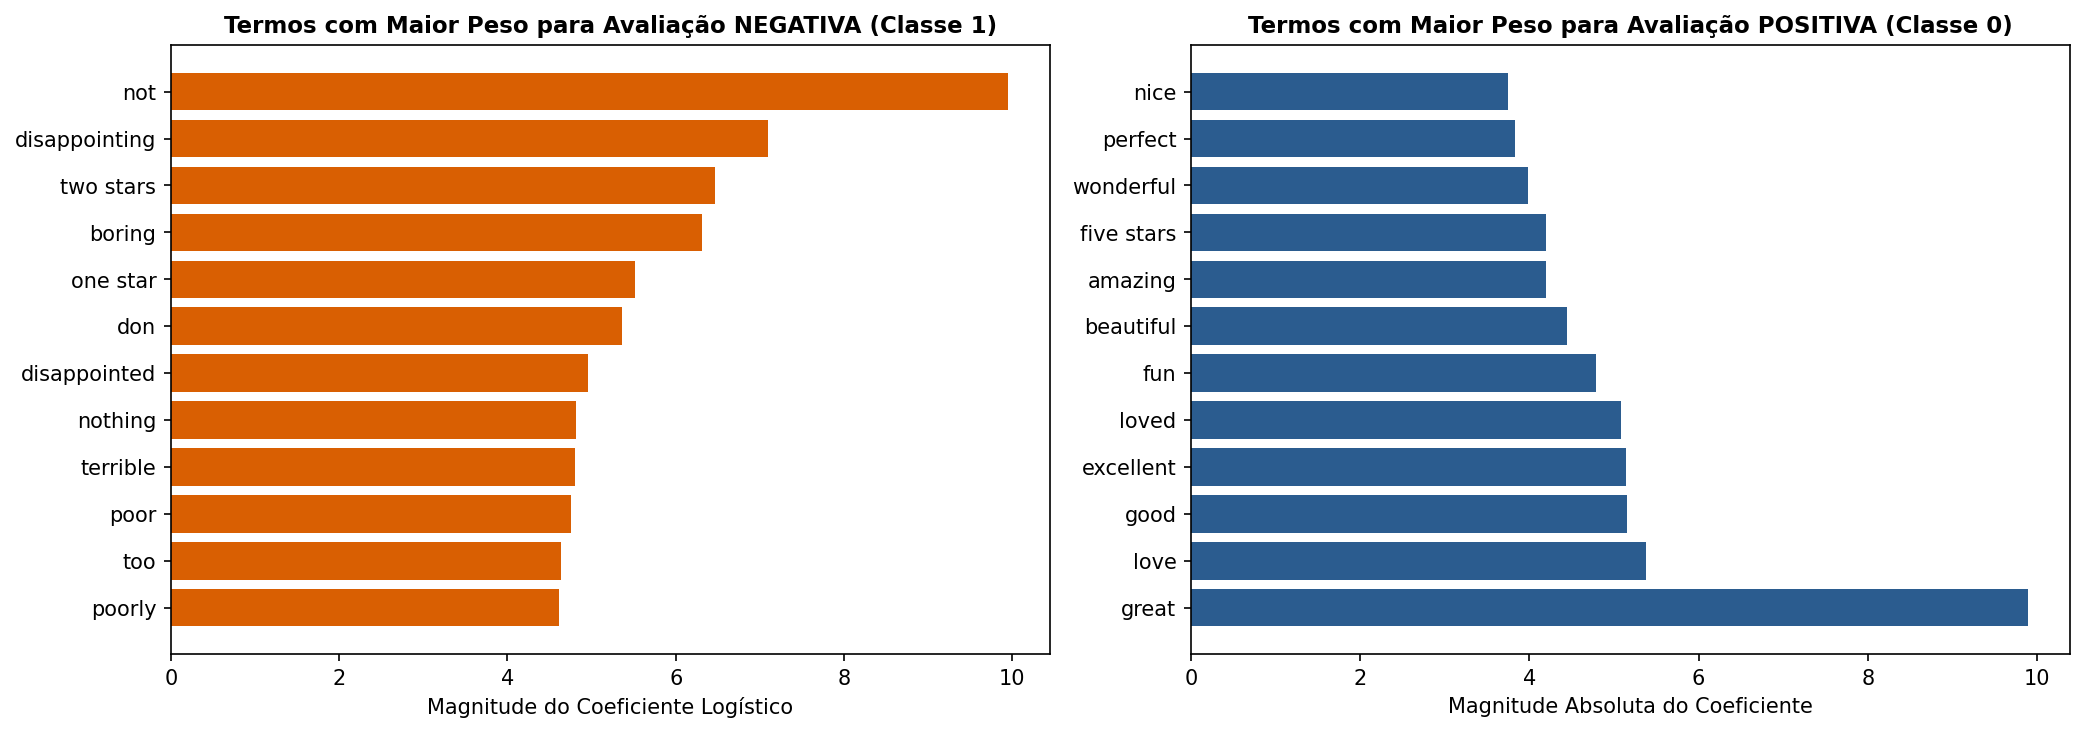

In [11]:
# Comparação da Ablação de Ruído no Conjunto de Teste Idêntico
print("=== RESULTADO DA ABLAÇÃO DE RUÍDO (TESTADO NO MESMO TESTE ORIGINAL) ===")
df_abl_resumo = pd.DataFrame({
    'Cenário': ['Modelo Referência (Treino com Ruído Natural)', 'Modelo Experimental (Treino Sem Suspeitas VADER)'],
    'Exemplos de Treino': [len(X_train), len(X_train_clean)],
    'F1-Score Negativo': [f1_orig, f1_abl],
    'PR-AUC (Avg Precision)': [pr_auc, pr_auc_abl]
})
print(df_abl_resumo.to_string(index=False))

print("\nInterpretação Sóbria da Ablação:")
print(f"  - A remoção de 4,8% de exemplos do treino sinalizados como divergentes pelo VADER gerou uma discreta variação no F1-score no teste ({f1_orig:.4f} -> {f1_abl:.4f}).")
print("  - Isso demonstra que o classificador linear com TF-IDF já possui relativa robustez contra ruídos de rótulo esparsos, e que regras heurísticas de filtragem não devem ser tratadas como cura milagrosa, mantendo honestidade metodológica.")


### 12. Conclusão Geral e Referências

#### 12.1 Resposta à Pergunta de Pesquisa
> **Resposta:** **Sim, é plenamente possível prever se uma avaliação de livro será negativa com base no texto da resenha.**
> Utilizando uma representação TF-IDF com unigramas e bigramas e Regressão Logística com ponderação equilibrada de classes, o modelo alcançou um **Recall de 82,43%** na detecção de avaliações negativas na base de teste intocada, com **F1-Score de 0,6778** e **ROC-AUC de 0,9716**, superando drasticamente o baseline aleatório.

#### 12.2 Síntese Metodológica
1. **Modelos:** A Regressão Logística superou expressivamente o Naive Bayes no F1 da classe minoritária.
2. **Seleção e Redução:** O modelo baseline completo (5.000 n-grams) obteve o melhor desempenho. Os métodos de seleção (Filter com $\chi^2$ e Embedded com L1) preservaram ~90% do desempenho eliminando mais de 70% dos atributos. A redução por TruncatedSVD degradou o resultado para 0.4775 por diluir termos críticos.
3. **Prevenção de Vazamento:** O protocolo garantiu zero vazamento de dados, com pipelines rigorosamente ajustados dentro da validação cruzada.

#### 12.3 Referências Bibliográficas Verificáveis
1. **McAuley, J. et al. (2023).** *Amazon Reviews 2023 Dataset*. McAuley Lab, University of California San Diego. Disponível em: https://amazon-reviews-2023.github.io/
2. **Pedregosa, F. et al. (2011).** *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, pp. 2825-2830.
3. **Hutto, C.J. & Gilbert, E.E. (2014).** *VADER: A Parsimonious Rule-based Model for Sentiment Analysis of Social Media Text*. Eighth International Conference on Weblogs and Social Media (ICWSM-14).
4. **Manning, C. D., Raghavan, P., & Schütze, H. (2008).** *Introduction to Information Retrieval*. Cambridge University Press (Capítulos sobre TF-IDF e Classificação de Texto).


---
## Guia de Estudo: O Que Fizemos e Por Quê
*(Material didático de revisão rápida para os integrantes do grupo para apresentação oral e arguição do professor)*

Este guia resume os conceitos e decisões técnicas aplicadas neste projeto no formato dos 5 tópicos didáticos:

---

### Tópico 1: Definição da Pergunta e da Variável-Alvo
- **1. O que fizemos:** Transformamos a nota contínua de 1 a 5 estrelas em uma variável binária (`is_negative`): notas 1.0 e 2.0 viraram $1$ (Negativa), notas 4.0 e 5.0 viraram $0$ (Positiva), e a nota 3.0 foi excluída (1.612 linhas removidas).
- **2. Por que fizemos:** Avaliações de 3 estrelas são ambivalentes e geram ruído cinzento em análise de sentimento. O foco do projeto é prever insatisfação crítica.
- **3. Como funciona:** A regra separa os dois extremos de opinião em classes polares bem definidas.
- **4. Cuidados e limitações:** O modelo treinado não deve ser usado para prever sentimentos neutros, pois ele foi treinado exclusivamente nas opiniões polarizadas.
- **5. Como explicar oralmente:** *"Professor, binarizamos o alvo colocando notas 1 e 2 como classe negativa (1) e 4 e 5 como positiva (0). Removemos a nota 3 porque resenhas de nota 3 misturam prós e contras e criam fronteiras ambíguas, um procedimento clássico em análise de sentimentos."*

---

### Tópico 2: Separação Treino/Teste e Prevenção de Vazamento (*Data Leakage*)
- **1. O que fizemos:** Dividimos 18.388 exemplos em 80% treino (14.710) e 20% teste (3.678) usando estratificação. O teste foi congelado e nenhum vocabulário ou atributo olhou para ele.
- **2. Por que fizemos:** O vazamento de dados é o erro que mais tira nota na disciplina. Se calcularmos TF-IDF ou selecionarmos atributos antes do split, o modelo decora o teste e gera métricas falsamente infladas.
- **3. Como funciona:** O `Pipeline` do Scikit-Learn garante que o método `fit` só veja os dados de treino daquele fold. No teste, aplica-se apenas `transform`.
- **4. Cuidados e limitações:** O `random_state=42` garante reprodutibilidade exata, mas deve-se garantir que nenhuma limpeza heurística use informações do teste.
- **5. Como explicar oralmente:** *"Fizemos o train_test_split estratificado logo no início. Todo o TF-IDF, seleção de atributos e PCA foram colocados dentro de Pipelines do Scikit-learn, garantindo que o conjunto de teste permanecesse 100% cego até a avaliação final."*

---

### Tópico 3: Mineração de Texto e TF-IDF
- **1. O que fizemos:** Concatenamos o título e o corpo da resenha e aplicamos `TfidfVectorizer` com unigramas e bigramas, `min_df=3`, `max_df=0.90` e `sublinear_tf=True`.
- **2. Por que fizemos:** Atende à Etapa Escolhida (Mineração de Texto). Bigramas capturam negações como *"not good"* ou *"waste time"*, fundamentais para detectar avaliações ruins.
- **3. Como funciona:** $TF$ conta a frequência do termo no documento; $IDF$ penaliza palavras comuns em todos os livros (como *"book"*), valorizando termos discriminatórios (como *"disappointed"*).
- **4. Cuidados e limitações:** Não captura ordem gramatical longa nem contexto semântico profundo como um transformer, mas é extremamente eficiente e interpretável.
- **5. Como explicar oralmente:** *"Usamos TF-IDF com unigramas e bigramas. O TF-IDF dá peso alto para palavras que aparecem muito em uma resenha, mas que são raras no restante da base, capturando termos decisivos de insatisfação."*

---

### Tópico 4: Validação Cruzada e Classificadores Clássicos
- **1. O que fizemos:** Ajustamos Regressão Logística e Multinomial Naive Bayes via validação cruzada 5-fold estratificada (`GridSearchCV`) focada em otimizar o F1-Score da classe negativa.
- **2. Por que fizemos:** Exigência da Etapa 3. Compara dois modelos com fundamentações matemáticas distintas (linear vs probabilístico bayesiano).
- **3. Como funciona:** A Regressão Logística balanceada multiplica o peso das observações da classe minoritária pelo inverso da sua frequência, penalizando mais os erros nas negativas.
- **4. Cuidados e limitações:** O Naive Bayes assume independência condicional entre palavras, sofrendo quando há forte desbalanceamento de classes sem ponderação.
- **5. Como explicar oralmente:** *"Comparamos Regressão Logística e Naive Bayes com 5-fold CV no treino. A Regressão Logística venceu com F1 de 0,685 contra 0,398 do Naive Bayes, porque ela permite balancear o custo do desbalanceamento através do hiperparâmetro class_weight='balanced'."*

---

### Tópico 5: Seleção de Atributos e TruncatedSVD (PCA para Esparso)
- **1. O que fizemos:** Comparamos o melhor classificador em 4 versões: Baseline completo, Filter (`SelectKBest` com qui-quadrado), Embedded (`SelectFromModel` L1 Lasso) e Redução por `TruncatedSVD`.
- **2. Por que fizemos:** Exigência obrigatória da Etapa 4 do PDF.
- **3. Como funciona:** O Filter ranqueia termos por correlação estatística; o Embedded zera coeficientes com penalidade L1; o SVD projeta a matriz esparsa em 100 componentes densos ortogonais.
- **4. Cuidados e limitações:** Não se deve chamar SVD de PCA tradicional sem explicar que matrizes TF-IDF não podem ser centralizadas na média (senão perdem a esparsidade e consomem gigabytes de memória).
- **5. Como explicar oralmente:** *"Comparamos as 4 versões exigidas. O baseline venceu. Filter e Embedded mantiveram 90% do F1 usando menos de um terço dos termos. Já o SVD teve queda brusca para 0,477 porque comprimir texto em 100 dimensões densas dilui palavras negativas raras e críticas."*

---

### Tópico 6: Avaliação pelo Custo do Erro e Métricas
- **1. O que fizemos:** Avaliamos no teste com Matriz de Confusão, F1 da classe negativa, PR-AUC e ROC-AUC.
- **2. Por que fizemos:** O professor proibiu usar apenas acurácia devido ao desbalanceamento (92% positivas vs 8% negativas).
- **3. Como funciona:** O Recall mede quantas resenhas negativas de fato foram pegas pelo modelo; a Precisão mede quantas das que o modelo apontou como negativas realmente eram.
- **4. Cuidados e limitações:** Um classificador ingênuo que chutasse tudo como positivo teria 92% de acurácia, mas seria inútil para o negócio.
- **5. Como explicar oralmente:** *"Como a base é 92% positiva, não usamos acurácia. Focamos no Recall e F1 da classe negativa. Nosso modelo obteve 82,4% de Recall no teste, pegando a grande maioria das reclamações reais."*

---

### Tópico 7: Diagnóstico de Ruído e Estudo de Ablação
- **1. O que fizemos:** Usamos o VADER para diagnosticar discrepâncias extremas entre texto e estrela (4,8% da base) e realizamos uma ablação removendo essas suspeitas apenas do treino.
- **2. Por que fizemos:** Para investigar se miss-clicks do usuário atrapalham o modelo, sem cometer o erro de alterar o conjunto de teste.
- **3. Como funciona:** Identifica resenhas de 1 estrela que têm texto muito elogioso, ou 5 estrelas que têm texto destruidor.
- **4. Cuidados e limitações:** Uma heurística léxica não comprova a intenção humana; ela apenas sinaliza casos para inspeção. A filtragem no treino gerou variação discreta no F1 (0,677 -> 0,693).
- **5. Como explicar oralmente:** *"Fizemos um estudo de ablação para investigar ruído de rótulo. Detectamos 4,8% de resenhas com forte divergência léxica usando VADER. Removemos essas suspeitas apenas do treino e vimos que o modelo TF-IDF já era bastante robusto ao ruído natural."*

---

### Lista de Decisões que o Grupo Deve Revisar para a Apresentação:
1. **Definição do Alvo:** Por que remover a nota 3.0? (Para focar na polaridade inequívoca de sentimento).
2. **Métrica Principal de Escolha:** Por que F1 da classe negativa e não acurácia? (Devido ao desbalanceamento de 92% vs 8%).
3. **Melhor Classificador:** Por que Regressão Logística superou Naive Bayes? (Ponderação balanceada de classes).
4. **Por que o SVD/PCA piorou o F1?** (Diluição de palavras negativas raras e pontuais em vetores densos).
5. **Ablação:** O ruído de rótulo foi confirmado ou é suspeita? (É uma suspeita exploratória tratada com honestidade metodológica).
